In [ ]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.11.0+cu130
Device: cuda


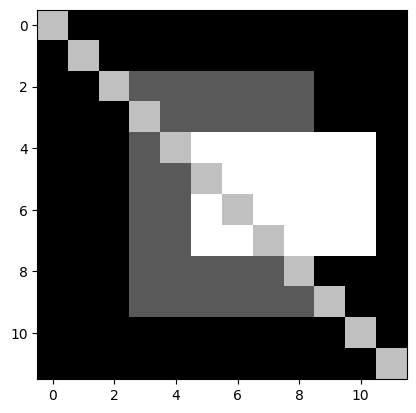

In [ ]:
tiny_image = np.zeros((12, 12), dtype=np.float32)

tiny_image[2:10, 3:9] = 0.35
tiny_image[4:8, 5:11] = 1.00
np.fill_diagonal(tiny_image, 0.75)


plt.imshow(tiny_image, cmap='gray')
plt.show()

In [ ]:
X = torch.tensor([
    [1., 1., 1., 0., 0.],
    [0., 1., 1., 1., 0.],
    [0., 0., 1., 1., 1.],
    [0., 0., 1., 1., 0.],
    [0., 1., 1., 0., 0.],
])

K = torch.tensor([
    [1., 0., -1.],
    [1., 0., -1.],
    [1., 0., -1.],
])


In [ ]:
def convolution(image, kernel):
    kernel_height, kernel_width = kernel.shape
    output_height = image.shape[0] - kernel_height + 1
    output_width = image.shape[1] - kernel_width + 1

    output = torch.zeros((output_height, output_width))

    for row in range(output_height):
        for col in range(output_width):
            patch = image[row:row+kernel_height, col:col+kernel_width]
            output[row, col] = (patch * kernel).sum()
    return output

manual_output = convolution(X, K)
manual_output

tensor([[-2.,  0.,  2.],
        [-3., -2.,  2.],
        [-3., -1.,  2.]])

In [ ]:
# pytorch format - NxCxHxW
X_3d = X.unsqueeze(0)#.unsqueeze(0)
K_4d = K.unsqueeze(0).unsqueeze(0)
F.conv2d(X_3d, K_4d)

tensor([[[-2.,  0.,  2.],
         [-3., -2.,  2.],
         [-3., -1.,  2.]]])

In [ ]:
X.unsqueeze(0).shape

torch.Size([1, 5, 5])

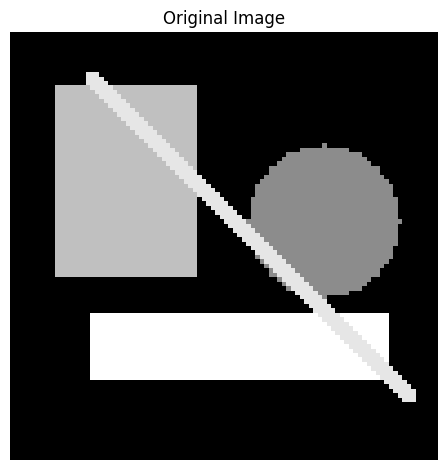

In [ ]:
def make_shape_image(size=96):
    image = np.zeros((size, size), dtype=np.float32)
    image[12:55, 10:42] = 0.75
    image[63:78, 18:85] = 1.0

    rows, cols = np.ogrid[:size, :size]
    circle = (rows - 42) ** 2 + (cols - 70) ** 2 <= 17 ** 2
    image[circle] = 0.55

    for index in range(10, 82):
        row = index
        col = min(size - 1, index + 8)
        image[max(0, row - 1):row + 2, max(0, col - 1):col + 2] = 0.9

    return torch.tensor(image)

shape_image = make_shape_image()
plt.imshow(shape_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:

sobel_x = torch.tensor([
    [-1., 0., 1.],
    [-2., 0., 2.],
    [-1., 0., 1.],
])

sobel_y = torch.tensor([
    [-1., -2., -1.],
    [ 0.,  0.,  0.],
    [ 1.,  2.,  1.],
])

blur = torch.ones(3, 3) / 9

sharpen = torch.tensor([
    [ 0., -1.,  0.],
    [-1.,  5., -1.],
    [ 0., -1.,  0.],
])

In [ ]:
blur

tensor([[0.1111, 0.1111, 0.1111],
        [0.1111, 0.1111, 0.1111],
        [0.1111, 0.1111, 0.1111]])

In [ ]:
def apply_single_filter(image_2d, kernel_2d, padding=1):
    image_4d = image_2d[None, None, :, :]
    kernel_4d = kernel_2d[None, None, :, :]
    return F.conv2d(
        image_4d,
        kernel_4d,
        padding=padding,
    ).squeeze()

In [ ]:
sobel_x_output = apply_single_filter(shape_image, sobel_x)
sobel_y_output = apply_single_filter(shape_image, sobel_y)
edge_magnitude = torch.sqrt(sobel_x_output ** 2 + sobel_y_output ** 2)

blur_output = apply_single_filter(shape_image, blur)
sharpen_output = apply_single_filter(shape_image, sharpen)



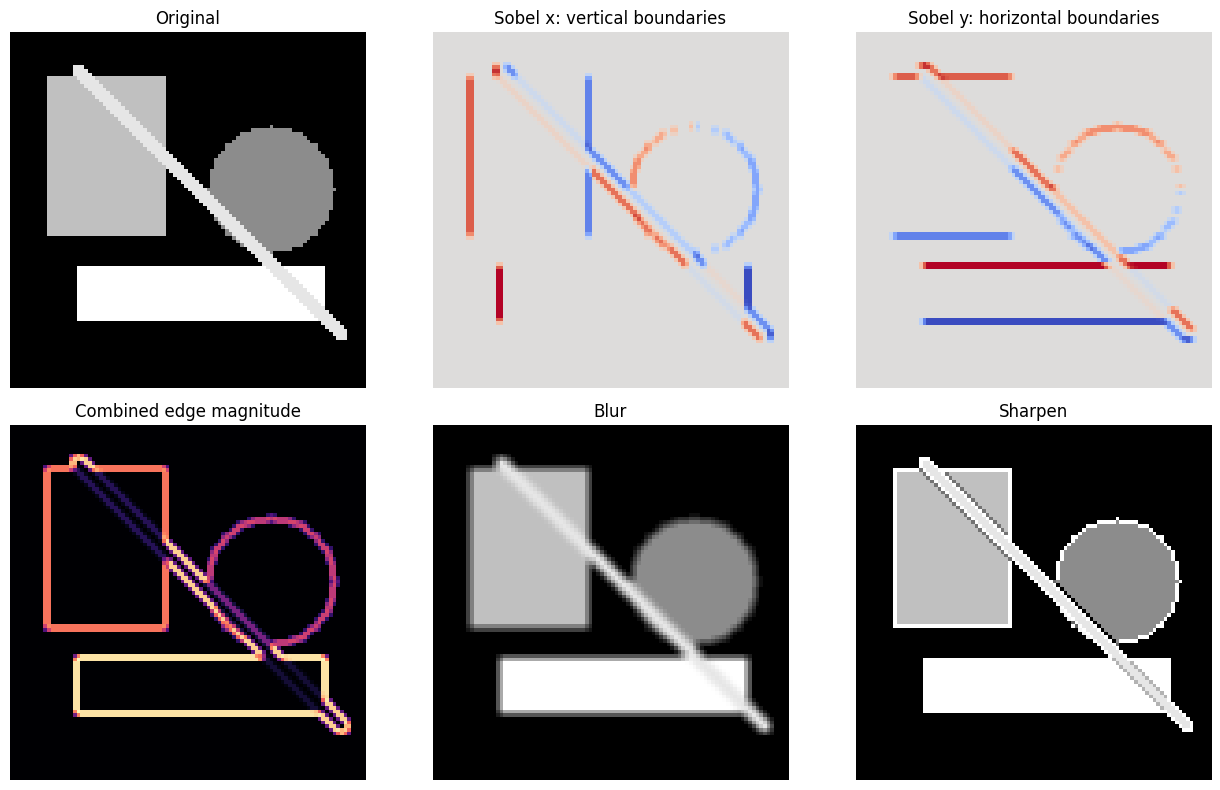

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))

plots = [
    (shape_image, "Original", "gray"),
    (sobel_x_output, "Sobel x: vertical boundaries", "coolwarm"),
    (sobel_y_output, "Sobel y: horizontal boundaries", "coolwarm"),
    (edge_magnitude, "Combined edge magnitude", "magma"),
    (blur_output, "Blur", "gray"),
    (sharpen_output.clamp(0, 1), "Sharpen", "gray"),
]

for ax, (image, title, cmap) in zip(axes.ravel(), plots):
    ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# image as input, sobel image as output
torch.manual_seed(SEED)

teacher_kernel = sobel_x[None, None, :, :]
training_images = torch.rand(256, 1, 16, 16)

with torch.no_grad():
    target_edges = F.conv2d(
        training_images,
        teacher_kernel,
        padding=1,
    )

student_conv = nn.Conv2d(1, 1, kernel_size=3, padding=1, bias=False)
print("Initialized Kernel\n", student_conv.weight.detach().squeeze())

Initialized Kernel
 tensor([[ 0.1648,  0.2713,  0.2920],
        [ 0.0860, -0.2352,  0.0170],
        [ 0.1336, -0.2754, -0.2267]])


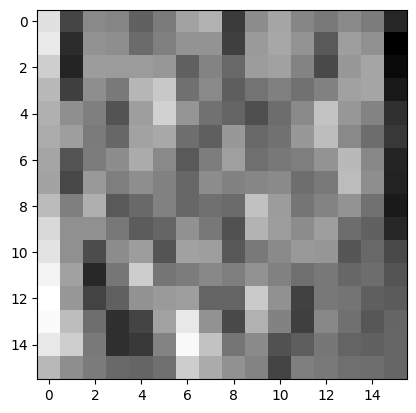

In [ ]:
plt.imshow(target_edges[0][0], cmap='gray')
plt.show()

In [ ]:
optimizer = torch.optim.Adam(student_conv.parameters(), lr=0.08)
loss_history = []

for step in range(200):
    predicted_edges = student_conv(training_images) # forward pass
    loss = F.mse_loss(predicted_edges, target_edges) # loss calculation

    optimizer.zero_grad()
    loss.backward()

    optimizer.step()

    loss_history.append(loss.item())

print("Final loss", loss_history[-1])

Final loss 5.151173931849939e-10


In [ ]:
print("learned kernel:\n", student_conv.weight.detach().squeeze())
print("\n")
print("Sobel kernel\n", sobel_x)

learned kernel:
 tensor([[-9.9998e-01, -8.6452e-06,  9.9999e-01],
        [-2.0000e+00, -9.2715e-06,  2.0000e+00],
        [-9.9998e-01, -2.0364e-05,  1.0000e+00]])


Sobel kernel
 tensor([[-1.,  0.,  1.],
        [-2.,  0.,  2.],
        [-1.,  0.,  1.]])


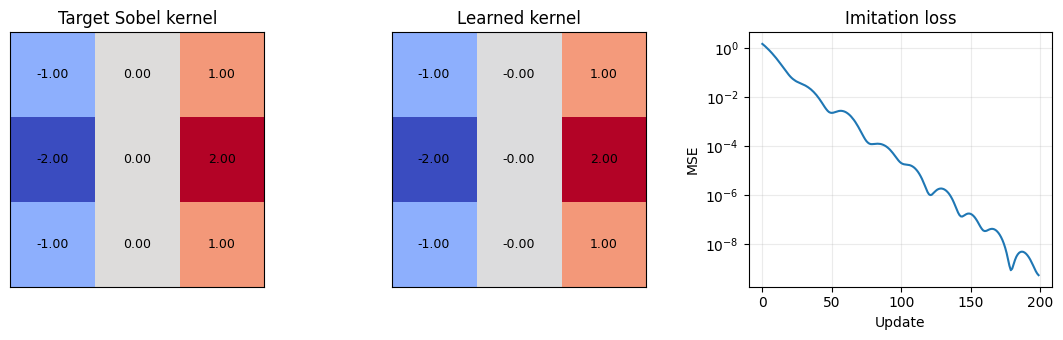

In [ ]:
learned_kernel = student_conv.weight.detach().squeeze()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))

for ax, kernel, title in [
    (axes[0], sobel_x, "Target Sobel kernel"),
    (axes[1], learned_kernel, "Learned kernel"),
]:
    ax.imshow(kernel, cmap="coolwarm", vmin=-2, vmax=2)
    ax.set_title(title)
    for row in range(3):
        for col in range(3):
            ax.text(
                col, row, f"{kernel[row, col]:.2f}",
                ha="center", va="center", fontsize=9,
            )
    ax.set_xticks([])
    ax.set_yticks([])

axes[2].plot(loss_history)
axes[2].set_yscale("log")
axes[2].set_title("Imitation loss")
axes[2].set_xlabel("Update")
axes[2].set_ylabel("MSE")
axes[2].grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
# max pooling operations
pool_input = torch.tensor([[[[
    1., 3., 2., 0.,
], [
    4., 6., 5., 1.,
], [
    2., 1., 7., 3.,
], [
    0., 2., 4., 8.,
]]]])

pool_input

tensor([[[[1., 3., 2., 0.],
          [4., 6., 5., 1.],
          [2., 1., 7., 3.],
          [0., 2., 4., 8.]]]])

In [ ]:
F.max_pool2d(pool_input, 2, 2)

tensor([[[[6., 5.],
          [2., 8.]]]])

In [ ]:
import zipfile
import os

# Define the paths
zip_path = '/content/cifar-10-python.zip'
target_dir = '/content/data'

# Ensure target directory exists
os.makedirs(target_dir, exist_ok=True)

# Extract the zip file
print(f"Extracting {zip_path} to {target_dir}...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(target_dir)

print("Extraction complete. Let's verify files in data/")
print(os.listdir(target_dir))

Extracting /content/cifar-10-python.zip to /content/data...
Extraction complete. Let's verify files in data/
['cifar-10-batches-py']


In [ ]:
transforms = transforms.ToTensor()
full_training_data = datasets.CIFAR10(
    root='data',
    train=True,
    download=False,
    transform=transforms
)

test_data = datasets.CIFAR10(
    root='data',
    train=False,
    download=False,
    transform=transforms
)

class_names = full_training_data.classes
print("Classes loaded successfully:", class_names)

Classes loaded successfully: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
generator = torch.Generator().manual_seed(SEED)
training_data, validation_data = random_split(
    full_training_data,
    [45000, 5000],
    generator=generator
)

loader_options = {
    "batch_size":1024,
    "num_workers":2,
}

training_loader = DataLoader(training_data, shuffle=True, **loader_options) # kwargs
validation_loader = DataLoader(validation_data, shuffle=False, **loader_options)
test_loader = DataLoader(test_data, shuffle=False, **loader_options)

print("Train:", len(training_data))
print("Validation:", len(validation_data))
print("Test:", len(test_data))

Train: 45000
Validation: 5000
Test: 10000


In [ ]:
# 1 image = 32x32x3 floats, 1 float is 16 bit
# available memory - 8 GB VRAM
# how many images at once we can load

Image batch: torch.Size([1024, 3, 32, 32])
Label batch: torch.Size([1024])
Pixel range: (0.0, 1.0)


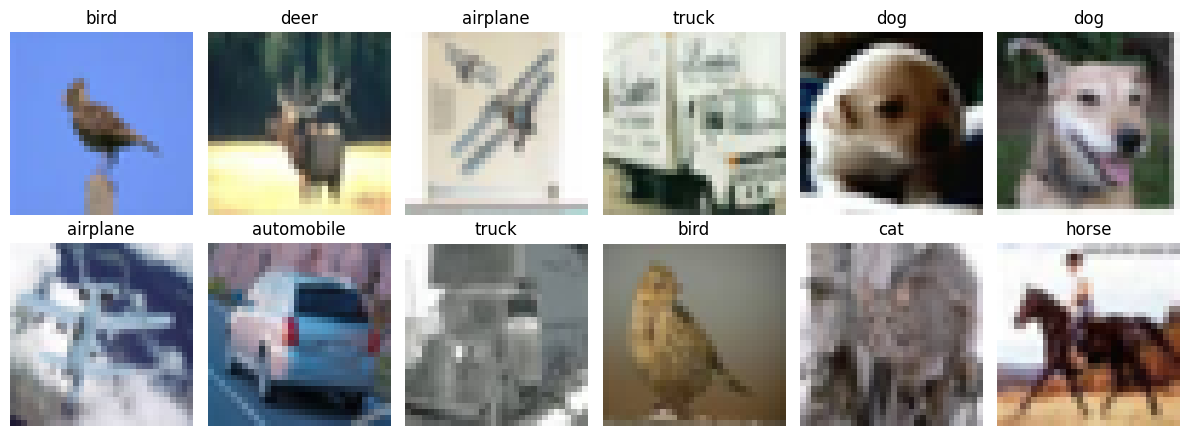

In [ ]:
images, labels = next(iter(training_loader))

print("Image batch:", images.shape)
print("Label batch:", labels.shape)
print("Pixel range:", (images.min().item(), images.max().item()))

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))

for ax, image, label in zip(
    axes.ravel(), images[:12], labels[:12]
):
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_names[label.item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# 3, 32, 32
# 0, 1,  2

# 1, 2, 0 - 32, 32, 3

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier1 = nn.Linear(1024, 512)
        self.relu1 = nn.ReLU()
        self.relu2 = nn.ReLU()
        self.classifier2 = nn.Linear(512, 256)
        self.classifier3 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        return self.classifier3(self.relu2(self.classifier2(self.relu1(self.classifier1(x)))))
model = SmallCNN().to(device)
model

SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier1): Linear(in_features=1024, out_features=512, bias=True)
  (relu1): ReLU()
  (relu2): ReLU()
  (classifier2): Linear(in_features=512, out_features=256, bias=True)
  (classifier3): Linear(in_features=256, out_features=10, bias=True)
)

In [ ]:
# 32x32x3 - conv2d - 32x32x16 -> Maxpool -> 16x16x16 -> conv2d -> 16x16x32 -> maxpool -> 8x8x32 -> Flatten ->2048

In [ ]:
total_weights = 0
for p in model.parameters():
    if p.requires_grad:
        total_weights += p.numel()
total_weights

723242

In [ ]:
def run_epoch(model, data_loader, loss_function, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    # get the data, forward pass, loss, compute gradient, update weights, update trackers
    for batch_images, batch_labels in data_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            # logits = model.forward(batch_images)
            logits = model(batch_images)
            loss = loss_function(logits, batch_labels)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = batch_labels.size(0)
        total_loss += loss.item() * batch_size

        total_correct += (logits.argmax(dim=1) == batch_labels).sum().item()
        total_examples += batch_size

    return {
        "loss":total_loss/total_examples,
        "accuracy": total_correct/total_examples
    }

In [ ]:
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 25
history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": [],
}

start_time = time.time()

for epoch in range(1, EPOCHS+1):
    train_metrics = run_epoch(model, training_loader, loss_function, optimizer)
    validation_metrics = run_epoch(model, validation_loader, loss_function)

    history["train_loss"].append(train_metrics["loss"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["validation_loss"].append(validation_metrics["loss"])
    history["validation_accuracy"].append(
        validation_metrics["accuracy"]
    )

    print(
        f"Epoch {epoch:02d} | "
        f"train loss {train_metrics['loss']:.4f} | "
        f"train acc {train_metrics['accuracy']:.3f} | "
        f"val loss {validation_metrics['loss']:.4f} | "
        f"val acc {validation_metrics['accuracy']:.3f}"
    )

print(f"Training time: {time.time() - start_time:.1f}s")

Epoch 01 | train loss 2.0903 | train acc 0.230 | val loss 1.8962 | val acc 0.320
Epoch 02 | train loss 1.7723 | train acc 0.346 | val loss 1.6607 | val acc 0.396
Epoch 03 | train loss 1.5966 | train acc 0.412 | val loss 1.5427 | val acc 0.447
Epoch 04 | train loss 1.4901 | train acc 0.453 | val loss 1.4614 | val acc 0.464
Epoch 05 | train loss 1.4211 | train acc 0.480 | val loss 1.4101 | val acc 0.496
Epoch 06 | train loss 1.3434 | train acc 0.510 | val loss 1.3333 | val acc 0.521
Epoch 07 | train loss 1.2799 | train acc 0.535 | val loss 1.2610 | val acc 0.545
Epoch 08 | train loss 1.2242 | train acc 0.556 | val loss 1.2247 | val acc 0.562
Epoch 09 | train loss 1.1802 | train acc 0.576 | val loss 1.2013 | val acc 0.569
Epoch 10 | train loss 1.1330 | train acc 0.591 | val loss 1.1396 | val acc 0.593
Epoch 11 | train loss 1.0875 | train acc 0.611 | val loss 1.1678 | val acc 0.581
Epoch 12 | train loss 1.0575 | train acc 0.622 | val loss 1.0786 | val acc 0.620
Epoch 13 | train loss 1.0154

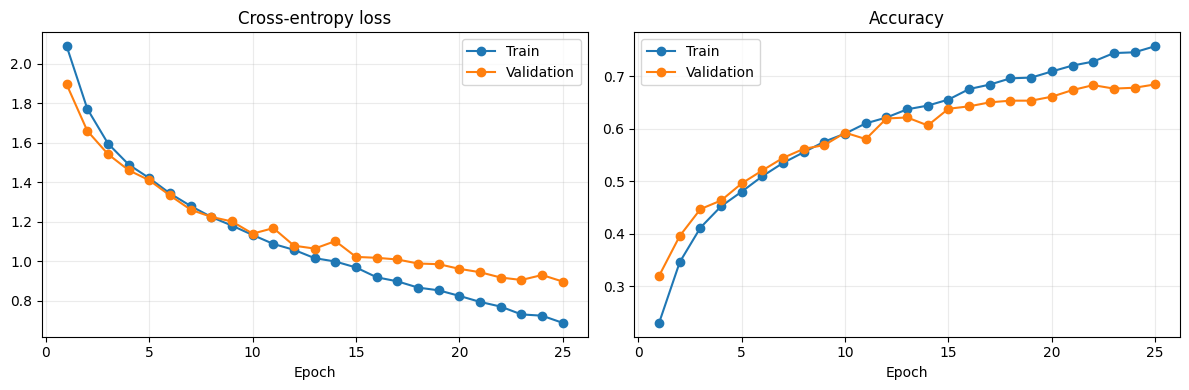

In [ ]:
epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    epochs, history["train_loss"],
    marker="o", label="Train",
)
axes[0].plot(
    epochs, history["validation_loss"],
    marker="o", label="Validation",
)
axes[0].set_title("Cross-entropy loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(
    epochs, history["train_accuracy"],
    marker="o", label="Train",
)
axes[1].plot(
    epochs, history["validation_accuracy"],
    marker="o", label="Validation",
)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
test_metrics = run_epoch(model, test_loader, loss_function)
print(f"Test loss:     {test_metrics['loss']:.4f}")
print(f"Test accuracy: {test_metrics['accuracy']:.3f}")

Test loss:     0.9053
Test accuracy: 0.682


In [ ]:
def collect_predictions(model, data_loader):
    model.eval()
    all_images = []
    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for batch_images, batch_labels in data_loader:
            logits = model(batch_images.to(device))
            probabilities = logits.softmax(dim=1).cpu()

            all_images.append(batch_images)
            all_labels.append(batch_labels)
            all_predictions.append(
                probabilities.argmax(dim=1)
            )
            all_probabilities.append(probabilities)

        return (
        torch.cat(all_images),
        torch.cat(all_labels),
        torch.cat(all_predictions),
        torch.cat(all_probabilities),
    )

(
    test_images,
    test_labels,
    test_predictions,
    test_probabilities,
) = collect_predictions(model, test_loader)

In [ ]:
!nvidia-smi

Sun Nov  1 05:56:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P0             28W /   70W |     815MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

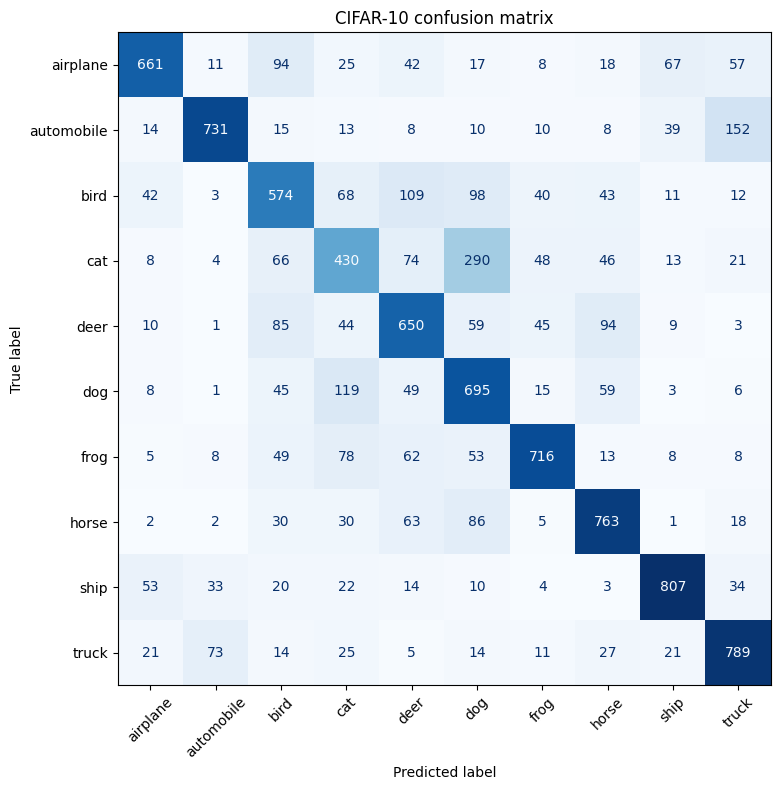

In [ ]:
matrix = confusion_matrix(
    test_labels,
    test_predictions,
)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(
    matrix,
    display_labels=class_names,
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
)
ax.set_title("CIFAR-10 confusion matrix")
plt.tight_layout()
plt.show()

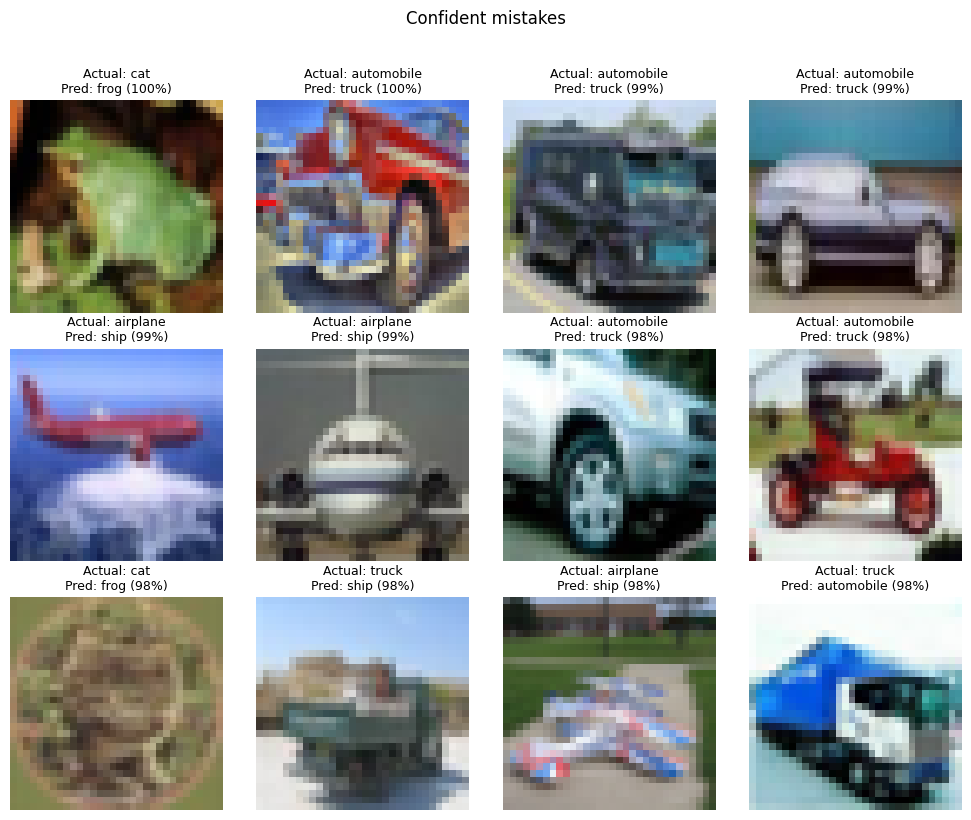

In [ ]:
wrong = torch.where(
    test_predictions != test_labels
)[0]
wrong_confidence = test_probabilities[
    wrong
].max(dim=1).values
most_confident_wrong = wrong[
    torch.argsort(
        wrong_confidence,
        descending=True,
    )[:12]
]

fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for ax, index in zip(
    axes.ravel(),
    most_confident_wrong,
):
    image = test_images[index].permute(1, 2, 0)
    actual = class_names[test_labels[index].item()]
    predicted = class_names[test_predictions[index].item()]
    confidence = test_probabilities[index].max().item()

    ax.imshow(image)
    ax.set_title(
        f"Actual: {actual}\n"
        f"Pred: {predicted} ({confidence:.0%})",
        fontsize=9,
    )
    ax.axis("off")

plt.suptitle("Confident mistakes", y=1.02)
plt.tight_layout()
plt.show()